# Week 9 - Multivariate Analysis, part 2

# 1. Lesson - no lesson this week

# 2. Weekly graph question

The graph below plots the first two principal component scores in a scatter plot.  What can be said about the three outliers in the upper left corner of the graph?  Is their first principal component score high or low?  What about their second principal component score?  What does that mean about their values in series_1, series_2, and series_3?  It seems to me that you can say something about series_3 (what can you say?) but you may have a harder time saying something about series_1 and series_2, and an almost impossible time saying anything about the relative values of series_1 and series_2.  Why is that?  How are series_1 and series_2 related, according to how they were created?  If you like, try drawing a pairplot for all three series and see what you get.

Overall, what are the advantages and disadvantages of the graph below?  Does it show anything interesting?

[0.79916477 0.18990532 0.01092991]
[[ 0.26541493  0.30096233  0.91595665]
 [ 0.60337553  0.6891417  -0.40127506]
 [ 0.75199261 -0.65917023 -0.00131519]]


Text(0, 0.5, 'Second Principal Component Score')

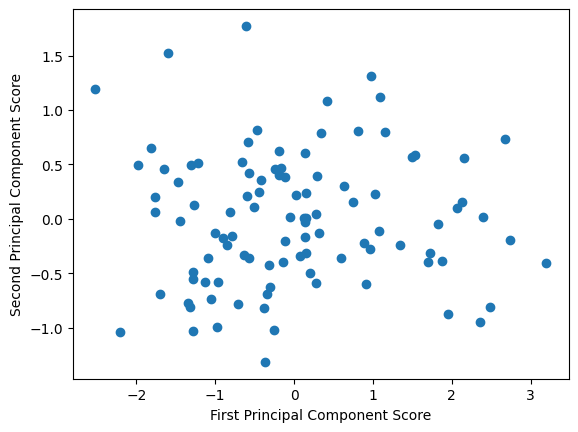

In [ ]:
import numpy as np
import pandas as pd
from sklearn import decomposition
import matplotlib.pyplot as plt

np.random.seed(0)
num_points = 100
series_1 = np.random.normal(loc = 2, scale = 0.5, size = num_points)
series_2 = series_1 * (1 + np.random.normal(loc = 0, scale = 0.1, size = num_points))
series_3 = series_1 * (1 + np.random.normal(loc = 0, scale = 0.5, size = num_points))
df = pd.DataFrame({'ser1': series_1, 'ser2': series_2, 'ser3': series_3})
df = df - df.mean() # set mean to zero, so we don't have to subtract mean from the principal component scores

pca3 = decomposition.PCA(n_components = 3)
pca3.fit(df)
print(pca3.explained_variance_ratio_)
print(pca3.components_)

first_principal_component_score = df.dot(pca3.components_[0])
second_principal_component_score = df.dot(pca3.components_[1])
plt.scatter(first_principal_component_score, second_principal_component_score)
plt.xlabel("First Principal Component Score")
plt.ylabel("Second Principal Component Score")

The three points in the upper left have low (negative) first principal component scores and high (positive) second scores. They seem to have low values in ser3, especially compared with ser1 and ser2. The first component gives a lot of weight to ser3.

It is harder to know the exact values of ser1 and ser2 from this graph. In the code, ser2 is created from ser1 with a little random change, so they are very similar. The small differences between them are mostly in the third component, which is not shown here.

I like that the PCA graph makes the unusual points easy to see and puts three variables into one 2D graph. The downside is that it is not easy to understand the original values, and some information is missing. I can see which points are unusual, but not exactly why without looking at the original data.

# 3. Working on your chosen project datasets this semester

This week, you will do the same types of exercises as last week, but you should use your chosen datasets that someone in your class found last semester. (They likely will not be the particular datasets that you found yourself.)

Here are some types of analysis you can do:
Draw heatmaps.

Draw bubble plots.

Perform Principal Component Analysis to find out the directions in which the data varies.  Can you represent the data using only its projection onto its first principal component, using the methods described in Week 8?  How much of the variance would this capture?

Try performing linear regression analysis using different sets of features.  Which features seem most likely to be useful to predict other features?

Conclusions:
Explain what conclusions you would draw from this analysis: are the data what you expect? Are the data likely to be usable? If the data are not useable, find some new data!

Do you see any outliers? (Data points that are far from the rest of the data).

Does the Principal Component Analysis suggest a way to represent the data using fewer dimensions than usual - using its first one or two principal component scores, perhaps?

Try using your correlation information from previous weeks to help choose features for linear regression.

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("ecuador_macro_long.csv")
wide = df.pivot(index="year", columns="indicator_name", values="value")
print("Number of years:", len(wide))
print("Missing values:")
print(wide.isna().sum())

Number of years: 31
Missing values:
indicator_name
cpi_index_2010_100                  0
fx_rate_lcus_per_usd                0
gdp_current_usd                     0
gdp_growth_annual_pct               0
household_consumption_growth_pct    0
inflation_cpi_annual_pct            0
oil_rents_pct_gdp                   4
population                          0
unemployment_pct                    0
dtype: int64


In [ ]:
data = wide[["gdp_growth_annual_pct", "household_consumption_growth_pct", "oil_rents_pct_gdp", "inflation_cpi_annual_pct", "unemployment_pct"]].dropna()
data.columns = ["GDP Growth", "Consumption Growth", "Oil Rents", "Inflation", "Unemployment"]
print("Years used for this analysis:", len(data))
print(data.head())

Years used for this analysis: 27
      GDP Growth  Consumption Growth  Oil Rents  Inflation  Unemployment
year                                                                    
1995      2.2525              3.9843     6.4537    22.9341         4.408
1996      1.7317              1.2647     7.7879    24.4115         4.422
1997      4.3279              5.9587     6.1722    30.6576         4.424
1998      3.2665              6.8838     3.2121    36.0984         4.389
1999     -4.7394            -12.1964     7.8633    52.2420         4.656


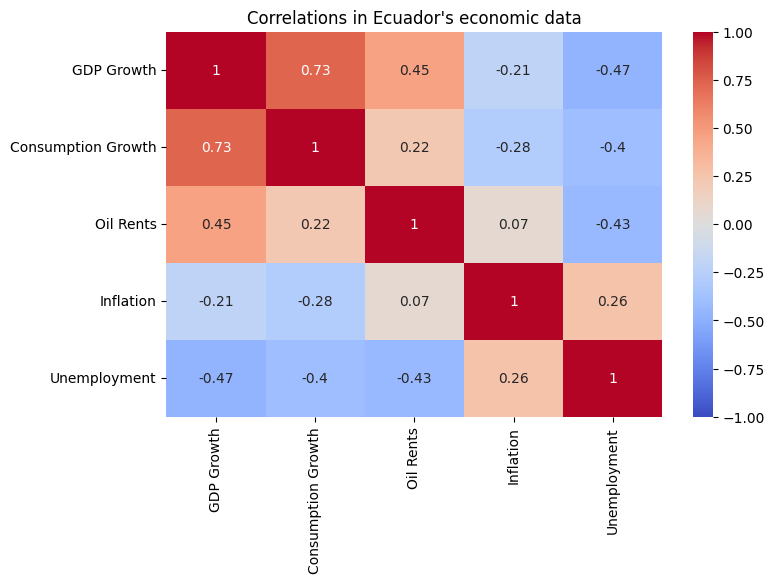

In [ ]:
import seaborn as sns

plt.figure(figsize=(8, 5))
sns.heatmap(data.corr(), annot=True, cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Correlations in Ecuador's economic data")
plt.show()

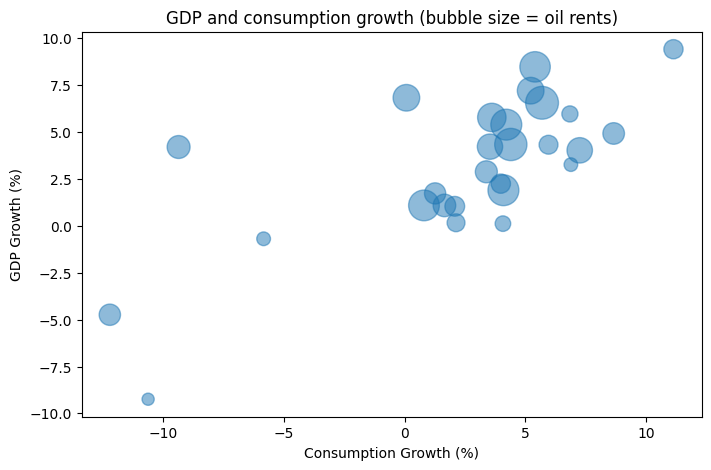

In [ ]:
plt.figure(figsize=(8, 5))
plt.scatter(data["Consumption Growth"], data["GDP Growth"], s=data["Oil Rents"] * 30, alpha=0.5)
plt.xlabel("Consumption Growth (%)")
plt.ylabel("GDP Growth (%)")
plt.title("GDP and consumption growth (bubble size = oil rents)")
plt.show()

First component: 49.3 %
First two components: 71.2 %


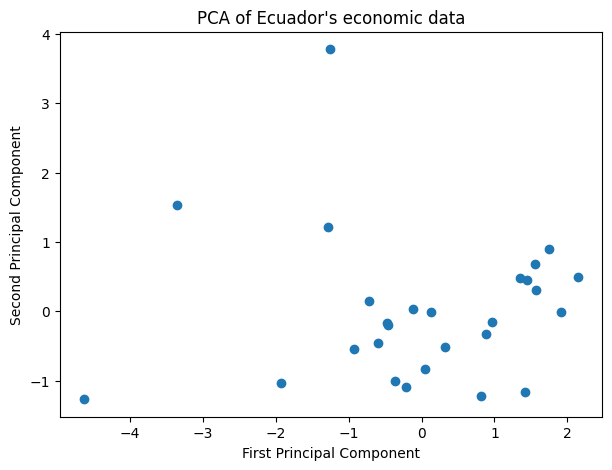

In [ ]:
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

scaled = StandardScaler().fit_transform(data)
pca = PCA(n_components=2)
scores = pca.fit_transform(scaled)
print("First component:", round(pca.explained_variance_ratio_[0] * 100, 1), "%")
print("First two components:", round(sum(pca.explained_variance_ratio_) * 100, 1), "%")
plt.figure(figsize=(7, 5))
plt.scatter(scores[:, 0], scores[:, 1])
plt.xlabel("First Principal Component")
plt.ylabel("Second Principal Component")
plt.title("PCA of Ecuador's economic data")
plt.show()

In [ ]:
from sklearn.linear_model import LinearRegression

features_to_try = {
    "Consumption Growth": ["Consumption Growth"],
    "Oil Rents": ["Oil Rents"],
    "Unemployment": ["Unemployment"],
    "All three": ["Consumption Growth", "Oil Rents", "Unemployment"]
}

for name, features in features_to_try.items():
    model = LinearRegression()
    model.fit(data[features], data["GDP Growth"])
    print(name, "R-squared:", round(model.score(data[features], data["GDP Growth"]), 2))

Consumption Growth R-squared: 0.53
Oil Rents R-squared: 0.21
Unemployment R-squared: 0.22
All three R-squared: 0.63


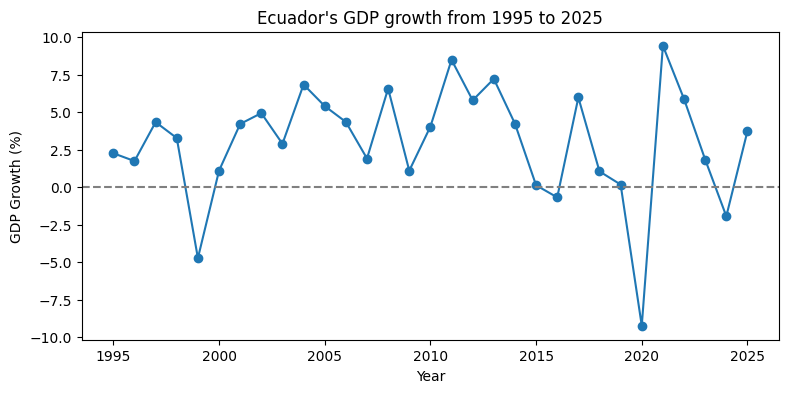

In [ ]:
plt.figure(figsize=(9, 4))
plt.plot(wide.index, wide["gdp_growth_annual_pct"], marker="o")
plt.axhline(0, color="gray", linestyle="--")
plt.xlabel("Year")
plt.ylabel("GDP Growth (%)")
plt.title("Ecuador's GDP growth from 1995 to 2025")
plt.show()

I used Ecuador's economic data from 1995 to 2025. The dataset has 31 years, but the oil rents information is missing for 2022 to 2025. For the graphs that compare all five indicators, I used the 27 years with complete data.

The heatmap shows that GDP growth and household consumption growth have a positive relationship. I can also see this in the bubble plot. In the linear regression, consumption growth had an R-squared of about 0.53. Oil rents had 0.21 and unemployment had 0.22. Using all three together increased the result to about 0.63. These numbers are from the same data used to fit the models, so I would need more testing before using them to predict future years.

With PCA, the first component explains about 49% of the variation. The first two together explain about 71%. I don't think one component is enough because it would lose about half of the information. Two components are better, but they still leave some information out.

I noticed a few unusual years. GDP growth was about -9.25% in 2020 and 9.42% in 2021. Inflation also reached about 96% in 2000. Overall, I think the dataset is useful, but I would check missing values and be careful when comparing years. The exchange rate also changes a lot around 2000, so I did not use it in these five-indicator comparisons. The graphs help show relationships, but they don't prove that one indicator causes another.

# 4. Storytelling With Data plot

Reproduce any graph of your choice in p. 136-150 of the Storytelling With Data book as best you can. ("The power of super-categories" to the end of chapter 5). You do not have to get the exact data values right, just the overall look and feel.

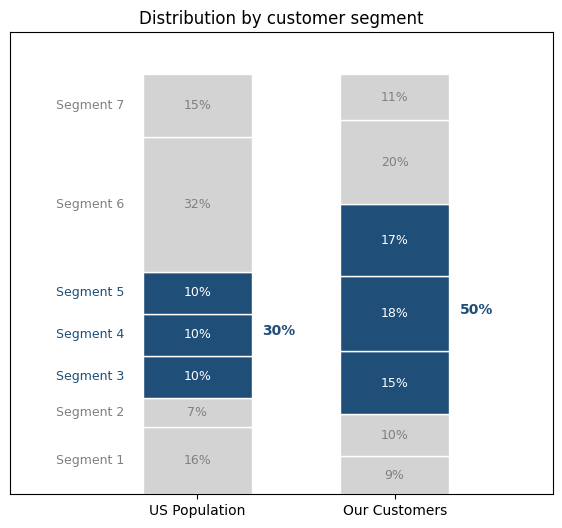

In [ ]:
import matplotlib.pyplot as plt

population = [16, 7, 10, 10, 10, 32, 15]
customers = [9, 10, 15, 18, 17, 20, 11]
colors = ["lightgray", "lightgray", "#1f4e79", "#1f4e79", "#1f4e79", "lightgray", "lightgray"]
bottom = [0, 0]

plt.figure(figsize=(7, 6))
for i in range(7):
    values = [population[i], customers[i]]
    plt.bar([0, 1], values, bottom=bottom, color=colors[i], width=0.55, edgecolor="white")
    for j in range(2):
        plt.text(j, bottom[j] + values[j] / 2, str(values[j]) + "%", ha="center", va="center", color="white" if 2 <= i <= 4 else "gray", fontsize=9)
    plt.text(-0.37, bottom[0] + values[0] / 2, "Segment " + str(i + 1), ha="right", va="center", fontsize=9, color="#1f4e79" if 2 <= i <= 4 else "gray")
    bottom = [bottom[j] + values[j] for j in range(2)]

plt.text(0.33, 38, "30%", color="#1f4e79", fontweight="bold")
plt.text(1.33, 43, "50%", color="#1f4e79", fontweight="bold")
plt.xticks([0, 1], ["US Population", "Our Customers"])
plt.yticks([])
plt.xlim(-0.95, 1.8)
plt.ylim(0, 110)
plt.title("Distribution by customer segment")
plt.show()

I chose figure 5.13 on page 148 of Storytelling with Data. I tried to copy the two stacked bars, the seven customer segments, and the blue color used to highlight segments 3, 4, and 5.